In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/raw/creditcard.csv")
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [4]:
for col in df.columns:
    print(f"{col} : {df[col].nunique()} : {df[col].isnull().sum()}")

Time : 124592 : 0
V1 : 275663 : 0
V2 : 275663 : 0
V3 : 275663 : 0
V4 : 275663 : 0
V5 : 275663 : 0
V6 : 275663 : 0
V7 : 275663 : 0
V8 : 275663 : 0
V9 : 275663 : 0
V10 : 275663 : 0
V11 : 275663 : 0
V12 : 275663 : 0
V13 : 275663 : 0
V14 : 275663 : 0
V15 : 275663 : 0
V16 : 275663 : 0
V17 : 275663 : 0
V18 : 275663 : 0
V19 : 275663 : 0
V20 : 275663 : 0
V21 : 275663 : 0
V22 : 275663 : 0
V23 : 275663 : 0
V24 : 275663 : 0
V25 : 275663 : 0
V26 : 275663 : 0
V27 : 275663 : 0
V28 : 275663 : 0
Amount : 32767 : 0
Class : 2 : 0


In [5]:
df['Class'].unique()

array([0, 1])

In [6]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [7]:
fraud_rate = df["Class"].value_counts(normalize=True) * 100
print(f"Fraud rate: {fraud_rate[1]:.2f}%")

Fraud rate: 0.17%


## Class Distribution

The dataset contains **284,807 transactions**, of which only **492 (0.17%)**
are fraudulent. This severe class imbalance is a key challenge in fraud
detection and will influence our choice of metrics and modeling strategy.

> ⚠️ Accuracy is not a useful metric here — a model that predicts
> everything as legitimate would achieve 99.83% accuracy while missing
> all fraud cases.

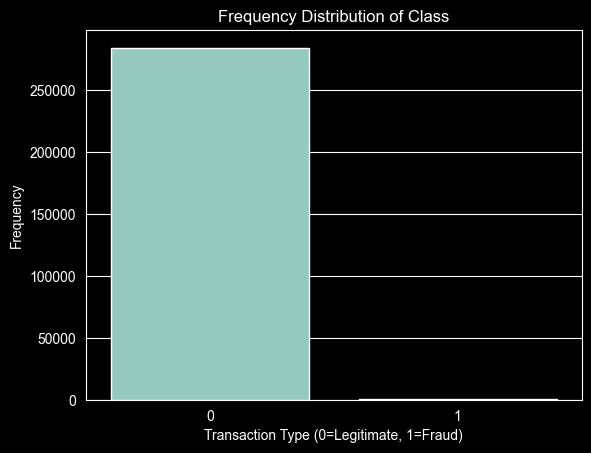

In [8]:
sns.countplot(x="Class", data=df)
plt.xlabel("Transaction Type (0=Legitimate, 1=Fraud)")
plt.ylabel("Frequency")
plt.title("Frequency Distribution of Class")
plt.show()

In [9]:
df["Amount"].describe()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

In [10]:
df.groupby("Class")['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


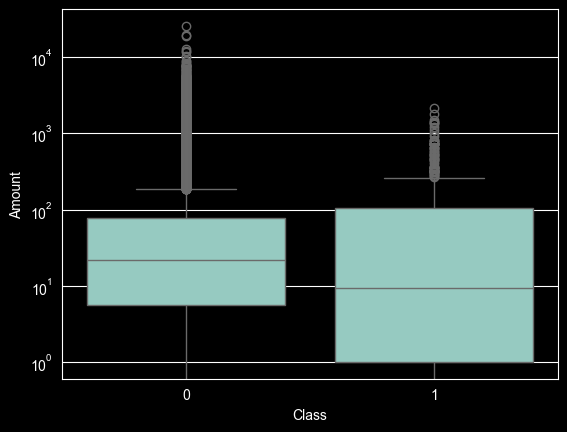

In [11]:
sns.boxplot(x="Class", y="Amount", data=df)
plt.yscale('log')
plt.show()

## Transaction Amount Analysis

Fraudulent transactions (Class=1) tend to have a **lower median amount** (~$9)
compared to legitimate transactions (~$22). However, the spread is wider —
fraudsters sometimes make large transactions too.

> 💡 This suggests that `Amount` alone is not enough to detect fraud —
> we need to combine it with other features.

In [12]:
df["Hour"] = (df["Time"] / 3600) % 24

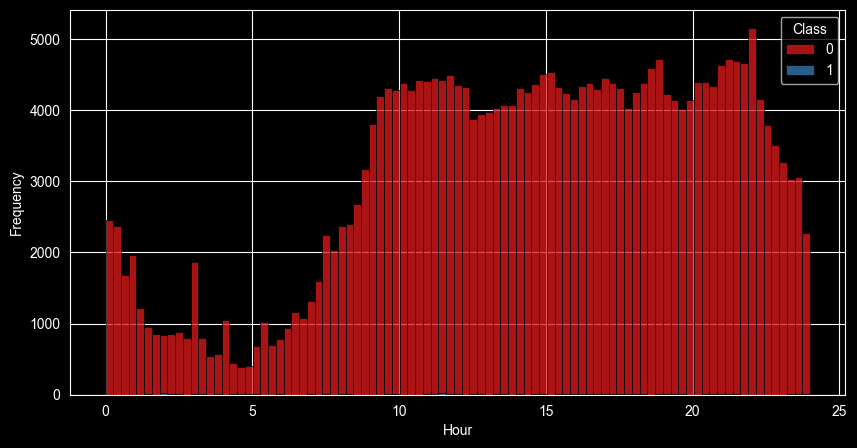

In [14]:
plt.figure(figsize=(10, 5))
sns.histplot(
    df,
    x="Hour",
    hue="Class",
    multiple="stack",
    palette="Set1",
    edgecolor="k",
    linewidth=0.5
)
plt.xlabel("Hour")
plt.ylabel("Frequency")
plt.show()


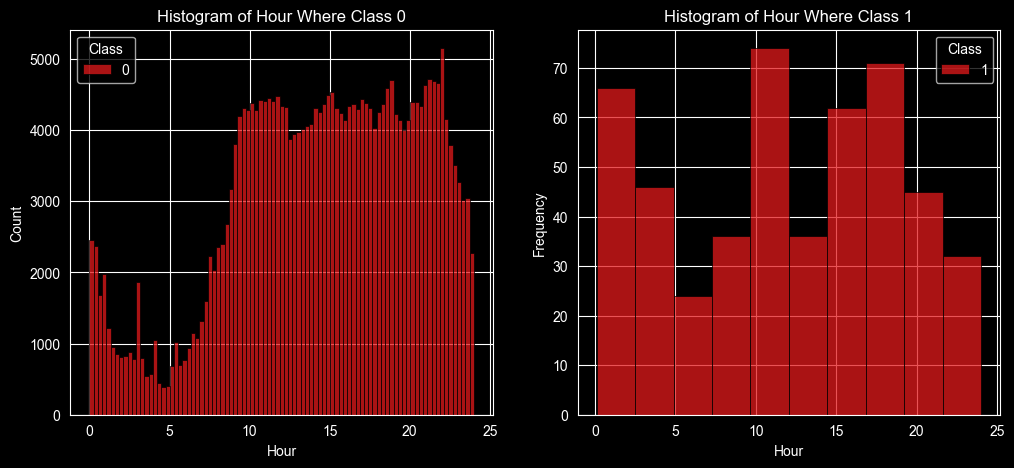

In [15]:
df1 = df[df["Class"] == 0]
df2 = df[df["Class"] == 1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(
    df1,
    x="Hour",
    hue="Class",
    multiple="stack",
    palette="Set1",
    edgecolor="k",
    linewidth=0.5,
    ax=ax1,
)
ax1.set_title("Histogram of Hour Where Class 0")

sns.histplot(
    df2,
    x="Hour",
    hue="Class",
    multiple="stack",
    palette="Set1",
    edgecolor="k",
    linewidth=0.5,
    ax=ax2,
)
ax2.set_title("Histogram of Hour Where Class 1")

plt.xlabel("Hour")
plt.ylabel("Frequency")
plt.show()




## Transaction Time Analysis

Fraudulent transactions show a different temporal pattern compared to
legitimate ones. While legitimate transactions peak during **daytime hours**
(9:00–22:00), fraud occurs more frequently at **night (0:00–5:00)** and
shows a secondary peak around **10:00–11:00**.

> 💡 This suggests that fraudsters exploit periods of low user activity.
> The `Hour` feature may be a useful signal for our model.

In [23]:
df['is_night'] = (df['Hour'] <= 6).astype(int)

In [24]:
corr_matrix = df.corr()
print(corr_matrix["Class"].sort_values())

V17        -0.326481
V14        -0.302544
V12        -0.260593
V10        -0.216883
V16        -0.196539
V3         -0.192961
V7         -0.187257
V18        -0.111485
V1         -0.101347
V9         -0.097733
V5         -0.094974
V6         -0.043643
Hour       -0.017082
Time       -0.012323
V24        -0.007221
V13        -0.004570
V15        -0.004223
V23        -0.002685
V22         0.000805
V25         0.003308
V26         0.004455
Amount      0.005632
V28         0.009536
V27         0.017580
V8          0.019875
V20         0.020090
is_night    0.025188
V19         0.034783
V21         0.040413
V2          0.091289
V4          0.133447
V11         0.154876
Class       1.000000
Name: Class, dtype: float64


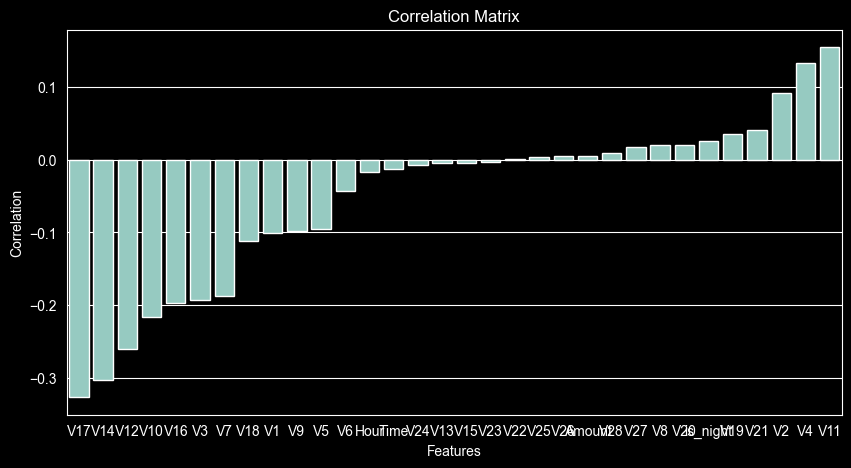

In [25]:
plt.figure(figsize=(10, 5))
corr = corr_matrix["Class"].sort_values().drop("Class")
sns.barplot(x=corr.index, y=corr.values)
plt.title("Correlation Matrix")
plt.xlabel("Features")
plt.ylabel("Correlation")
plt.show()

## Feature Correlation with Class

The bar chart shows the correlation of each feature with the target variable (`Class`).

- **V17, V14, V12** show the strongest **negative** correlation with fraud
- **V11, V4, V2** show the strongest **positive** correlation with fraud
- **Amount, Time, Hour** have near-zero correlation — weak predictors on their own

> 💡 Note: the sign of correlation doesn't indicate strength — V17 at -0.33
> is more informative than V4 at +0.13. These features will likely be
> the most important in our model.